# The product ρν and the Feller ratio φ for each maturity, and bisection against Brent

**TFG (BSc in Economics, Universitat Pompeu Fabra)** · Carles Aliern Fons · supervisor: Elisa Alòs

What this notebook does:

| | What | Where |
|---|---|---|
| 1 | The product ρ·ν of the Heston model for each maturity, on the 8 days of data | Section 2 |
| 2 | The Feller ratio φ = 2κθ/ν² for each maturity | Section 3 |
| 3 | Implied volatility by bisection vs Brent's method (`scipy.optimize.brentq`): time and precision | Section 4 |

The parameters come from the same calibration as section 3 of `exact_error_calibration.ipynb` (folder `Exact-error calibration`): exact error in implied volatility, maturity by maturity, with κ = 9.54 and θ = 0.0386 fixed. The data are the daily downloads of `..\Data` (the same 8 days). The notebook does not use the Internet.

**How to run it:** *Run All* in VS Code. The first time, section 1 repeats that calibration (about 7 minutes) and saves it to `params_by_maturity.csv`; after that it reads the file and everything takes a few seconds.

**Use of AI:** this code was written with the help of Claude (Anthropic) and checked by me; it reuses the functions of `exact_error_calibration.ipynb`.

## 0. Setup

In [1]:
import os                                     # file paths that work on Windows and Linux
import time                                   # to measure how long each step takes
import numpy as np                            # computation with vectors
import pandas as pd                           # tables
import matplotlib.pyplot as plt               # plots
from scipy.optimize import least_squares, brentq   # optimiser (calibration) and Brent's method (section 4)
import heston_tfg as ht                       # our library (the same file as in the other folders)

pd.set_option("display.width", 200)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 110})

DATA_FOLDER = os.path.join("..", "Data")      # the daily downloads, one subfolder per day
DAYS = ["2026-10-07", "2026-10-09", "2026-10-12", "2026-10-13",
        "2026-10-14", "2026-10-15", "2026-10-16", "2026-10-19"]   # the same 8 days as exact_error_calibration.ipynb
REF_DAY = "2026-10-12"                        # day used in section 4
KAPPA, THETA = 9.543, 0.0386                  # κ and θ fixed (global calibration with the vega approximation)
CACHE = "params_by_maturity.csv"              # the calibration of section 1 is saved here

## 1. Tools and the parameters of each maturity

The four functions are exactly those of `exact_error_calibration.ipynb` (`load_day`, `iv_bisection`, `iv_errors`, `calibrate`). Then we repeat its calibration: for each day and each maturity, ν, ρ and v0 with the exact error, κ and θ fixed.

In [2]:
def load_day(day):
    # Reads the SPX options of one day and returns (r, clean chain with the implied volatilities)
    raw = pd.read_csv(os.path.join(DATA_FOLDER, day, "SPX.csv.gz"))         # one row per option
    market = pd.read_csv(os.path.join(DATA_FOLDER, day, "market.csv"))       # a single row
    spot = float(market["spot_SPX"].iloc[0])                                 # index level at the close
    r = float(market["IRX_13w_tbill_pct"].iloc[0]) / 100                     # 13-week T-bill yield (in %) -> decimal (section 5 of exact_error_calibration.ipynb)
    raw["days"] = (raw["T"] * 365).round().astype(int)                      # days to expiry
    raw = raw[raw["days"] >= 2]                                              # out: options expiring today or tomorrow
    raw["root"] = raw["contractSymbol"].str[:-15]                            # "SPX" (AM) or "SPXW" (PM)
    has_spxw = raw.groupby("expiry")["root"].transform(lambda s: (s == "SPXW").any())
    raw = raw[(raw["root"] == "SPXW") | ~has_spxw]                           # SPXW when the expiry has it
    valid = (raw["bid"] > 0) & (raw["ask"] > raw["bid"])                     # live bid and ask
    n_valid = raw[valid].groupby("days").size()                              # number of valid quotes per expiry
    chosen = []
    for t in ht.TARGET_DAYS:                                                 # 2, 4, 7, ..., 365 days
        near = n_valid[(n_valid.index >= 0.85 * t - 1) & (n_valid.index <= 1.15 * t + 1)]   # expiries within ±15%
        if len(near) == 0:
            near = n_valid.iloc[[np.argmin(np.abs(n_valid.index - t))]]      # if none, the closest one
        chosen.append(int(near.idxmax()))                                    # the most liquid one
    raw = raw[raw["days"].isin(sorted(set(chosen)))]
    chain = ht.build_clean_chain(raw, spot, r=r)                             # forward, OTM options, implied vols, filters
    return r, chain


def iv_bisection(price, F, K, T, r, n_iter=60):
    # Black-76 implied volatility of many strikes at once: the σ is between 0.0001 and 5; we halve the interval 60 times
    low = np.full(len(K), 1e-4)                                              # lower end for each strike
    high = np.full(len(K), 5.0)                                              # upper end
    for _ in range(n_iter):
        mid = 0.5 * (low + high)                                             # midpoint
        too_high = ht.bs_call_fwd(F, K, T, mid, r) > price                   # is the Black-76 price with this σ too high?
        high = np.where(too_high, mid, high)                                 # yes: the right σ is on the left
        low = np.where(too_high, low, mid)                                   # no: it is on the right
    return 0.5 * (low + high)                                                # the centre of the final interval


def iv_errors(p, chain, r):
    # Exact error σ_model − σ_market of every option in `chain` (all its maturities)
    errors = []
    for T, g in chain.groupby("T"):                                          # one maturity at a time
        F, K = g["F"].iloc[0], g["K"].values                                 # forward and strikes
        prices = ht.heston_call_fwd(F, K, T, r, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])   # Heston price (Fourier)
        errors.append(iv_bisection(prices, F, K, T, r) - g["iv"].values)    # implied vol of the model − market
    return np.concatenate(errors)


def calibrate(chain, r, fixed, starts):
    # Minimises Σ(σ_model − σ_market)² over the free parameters; `fixed` = {name: value} that are not touched
    free = [n for n in ht.PARAM_NAMES if n not in fixed]                    # parameters we look for
    pos = [ht.PARAM_NAMES.index(n) for n in free]                           # their position (for the bounds)
    scale = {"kappa": 1.0, "theta": 0.05, "nu": 0.3, "rho": 0.3, "v0": 0.05}   # typical size of each parameter
    full = lambda x: {**fixed, **dict(zip(free, x))}                         # fixed + free -> the 5 parameters
    best = None
    for s in starts:                                                         # several starting points (local minima exist)
        x0 = np.clip([s[n] for n in free], ht.LOWER[pos] + 1e-6, ht.UPPER[pos] - 1e-6)
        sol = least_squares(lambda x: iv_errors(full(x), chain, r), x0,
                            bounds=(ht.LOWER[pos], ht.UPPER[pos]), x_scale=[scale[n] for n in free])
        if best is None or sol.cost < best.cost:                             # we keep the best one
            best = sol
    rmse = 100 * np.sqrt(np.mean(best.fun ** 2))                             # error in volatility points
    return full(best.x), rmse

In [3]:
if os.path.exists(CACHE):                                                    # already calibrated: read it
    by_maturity = pd.read_csv(CACHE)
    print(f"Read from {CACHE}: {len(by_maturity)} calibrations")
else:                                                                        # first time: the calibration of exact_error_calibration.ipynb
    fixed = {"kappa": KAPPA, "theta": THETA}
    p0 = {"nu": 1.9396, "rho": -0.605, "v0": 0.0096}                         # start 1: global values (vega approximation)
    starts_T = [p0, dict(p0, nu=3.0, rho=-0.5), dict(p0, nu=4.5, rho=-0.7)]  # starts 2 and 3: larger ν
    rows, t0 = [], time.time()
    for day in DAYS:
        r, chain = load_day(day)
        cal = ht.thin_chain(chain, max_per_T=40)                             # at most 40 options per maturity
        for T, g in cal.groupby("T"):                                        # each maturity separately
            p, rmse = calibrate(g, r, fixed, starts_T)
            rows.append(dict(day=day, days=int(round(T * 365)), nu=p["nu"], rho=p["rho"], v0=p["v0"], error=rmse))
    by_maturity = pd.DataFrame(rows)
    by_maturity.to_csv(CACHE, index=False)
    print(f"{len(by_maturity)} calibrations in {time.time() - t0:.0f} s, saved to {CACHE}")
by_maturity["horizon"] = [min(ht.TARGET_DAYS, key=lambda t: abs(t - d)) for d in by_maturity["days"]]   # closest target horizon

Read from params_by_maturity.csv: 102 calibrations


## 2. The product ρν for each maturity

In the Heston model, the ATM skew at very short maturities tends to ρν/(4σ0), with σ0 = √v0. The product ρν is therefore the part of the short-maturity skew that comes from the correlation and the volatility of volatility. If Heston with constant parameters were right, ρν would be the same at all maturities.

ρν (rows: target horizon in days; columns: day)


day,2026-10-07,2026-10-09,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-19
horizon,,,,,,,,
2,-1.57,-0.49,-1.41,-3.74,-3.82,NaN,-1.05,-3.56
4,-0.97,-1.42,-2.66,NaN,-2.20,-2.93,-1.75,-3.75
7,NaN,-1.73,-1.27,-1.29,NaN,-2.83,-2.36,-2.81
10,-1.44,-0.37,-1.38,-1.56,-1.95,NaN,-1.60,-3.12
14,-1.08,-1.28,NaN,-1.58,-1.85,-2.13,-2.38,NaN
21,-1.17,-1.31,-1.24,NaN,-1.15,-1.14,-1.32,-1.49
30,-0.87,-0.79,NaN,-1.15,-1.28,-1.25,-1.42,NaN
45,-0.87,-1.19,-1.23,-1.26,-1.36,-1.34,-1.48,-1.57
60,-1.09,NaN,-1.07,-1.08,-1.20,-1.15,-1.42,-1.38



ρν across the 8 days


,median,min,max
horizon,,,
2,-1.57,-3.82,-0.49
4,-2.20,-3.75,-0.97
7,-2.04,-2.83,-1.27
10,-1.56,-3.12,-0.37
14,-1.72,-2.38,-1.08
21,-1.31,-1.50,-0.99
30,-1.20,-1.42,-0.79
45,-1.30,-1.57,-0.87
60,-1.15,-1.42,-1.07


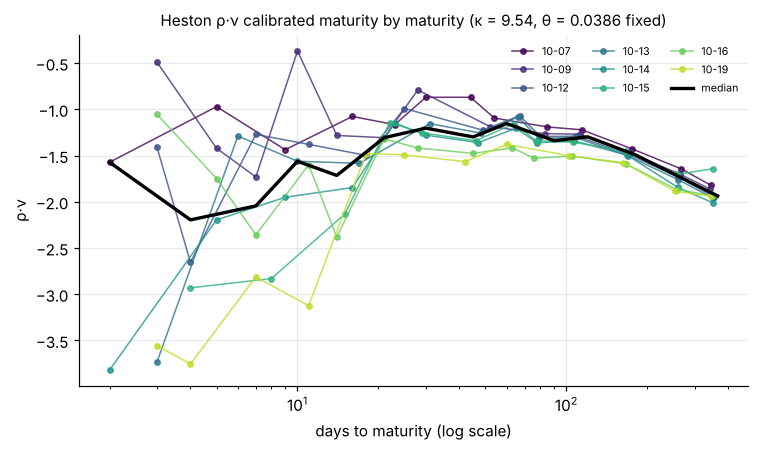

In [4]:
by_maturity["rho_nu"] = by_maturity["rho"] * by_maturity["nu"]             # the product ρ·ν
print("ρν (rows: target horizon in days; columns: day)")
display(by_maturity.pivot_table(index="horizon", columns="day", values="rho_nu").round(2))
summary = by_maturity.groupby("horizon")["rho_nu"].agg(["median", "min", "max"]).round(2)   # across the 8 days
print("\nρν across the 8 days")
display(summary)

fig, ax = plt.subplots(figsize=(7, 4.2))
colours = plt.cm.viridis(np.linspace(0, 0.9, len(DAYS)))                    # one colour per day
for day, c in zip(DAYS, colours):
    d = by_maturity[by_maturity["day"] == day].sort_values("days")
    ax.plot(d["days"], d["rho_nu"], "o-", ms=3.5, lw=1, color=c, alpha=0.8, label=day[5:])
med = by_maturity.groupby("horizon")["rho_nu"].median()                     # median over the days
ax.plot(med.index, med.values, "k-", lw=2.2, label="median")
ax.set_xscale("log"); ax.set_xlabel("days to maturity (log scale)"); ax.set_ylabel("ρ·ν")
ax.set_title(f"Heston ρ·ν calibrated maturity by maturity (κ = {KAPPA:.2f}, θ = {THETA:.4f} fixed)", fontsize=10)
ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.savefig("fig_rho_nu_by_maturity.png", dpi=150); plt.show()

## 3. The Feller ratio φ for each maturity

φ = 2κθ/ν². The condition holds if φ ≥ 1. With κ and θ fixed, 2κθ is the same number for all maturities, so φ only changes through ν.

In [5]:
by_maturity["phi"] = 2 * KAPPA * THETA / by_maturity["nu"] ** 2           # Feller ratio
print(f"2κθ = {2 * KAPPA * THETA:.3f}: the condition would need ν ≤ {np.sqrt(2 * KAPPA * THETA):.3f}")
print("\nφ (rows: target horizon in days; columns: day)")
display(by_maturity.pivot_table(index="horizon", columns="day", values="phi").round(3))
print(f"\nφ ≥ 1 in {int((by_maturity['phi'] >= 1).sum())} of {len(by_maturity)} calibrations; "
      f"largest φ = {by_maturity['phi'].max():.3f}, smallest φ = {by_maturity['phi'].min():.3f}")
print("Global calibrations of 12 October: vega approximation φ = 0.196; exact error φ = 0.084")

2κθ = 0.737: the condition would need ν ≤ 0.858

φ (rows: target horizon in days; columns: day)


day,2026-10-07,2026-10-09,2026-10-12,2026-10-13,2026-10-14,2026-10-15,2026-10-16,2026-10-19
horizon,,,,,,,,
2,0.044,0.047,0.036,0.029,0.030,NaN,0.194,0.029
4,0.107,0.096,0.032,NaN,0.049,0.032,0.094,0.029
7,NaN,0.029,0.094,0.102,NaN,0.029,0.046,0.048
10,0.068,0.074,0.078,0.087,0.075,NaN,0.115,0.035
14,0.156,0.102,NaN,0.092,0.087,0.057,0.044,NaN
21,0.134,0.099,0.166,NaN,0.240,0.214,0.175,0.144
30,0.274,0.230,NaN,0.162,0.187,0.166,0.149,NaN
45,0.354,0.185,0.182,0.184,0.179,0.172,0.149,0.140
60,0.215,NaN,0.149,0.149,0.174,0.152,0.142,0.172



φ ≥ 1 in 0 of 102 calibrations; largest φ = 0.354, smallest φ = 0.029
Global calibrations of 12 October: vega approximation φ = 0.196; exact error φ = 0.084


## 4. Implied volatility: bisection vs Brent

We take all the options of 12 October (the clean chain, call prices) and compute their Black-76 implied volatility in three ways, with the same search interval [0.0001, 5]:

- **Bisection, vectorised**: our `iv_bisection`, all the strikes of a maturity at once, 60 halvings.
- **Bisection, one option at a time**: the same algorithm, in a loop, to compare with Brent under the same conditions.
- **Brent**: `scipy.optimize.brentq`, one option at a time, tolerance 1e-12.

Each timing is the best of 5 repetitions.

In [6]:
r_ref, chain_ref = load_day(REF_DAY)                                         # clean options of 12 October and that day's interest rate r
prices, F, K, Tm = (chain_ref[c].values for c in ["call_mid", "F", "K", "T"])   # call price, forward, strike, maturity (numpy vectors)
n = len(chain_ref)                                                           # number of options (2,171)

def iv_bisection_vectorised():                                               # METHOD 1: our bisection, many strikes at once
    out = np.empty(n)                                                        # one volatility per option will go here
    for T_, idx in chain_ref.groupby("T").indices.items():                  # one maturity at a time (idx = positions of its options)
        out[idx] = iv_bisection(prices[idx], F[idx][0], K[idx], T_, r_ref)  # all the strikes of the maturity in a single call
    return out                                                               # implied volatilities of all the options

def iv_bisection_one_by_one():                                               # METHOD 2: the same bisection, option by option
    return np.array([iv_bisection(np.array([prices[i]]), F[i], np.array([K[i]]), Tm[i], r_ref)[0]   # one option at a time
                     for i in range(n)])                                     # loop over the n options

brent_iters = []                                                             # how many iterations Brent needs for each option
def iv_brent_one_by_one():                                                   # METHOD 3: Brent (scipy), option by option
    out = np.empty(n); brent_iters.clear()                                   # empty results and counter
    for i in range(n):                                                       # loop over the options
        f = lambda s: ht.bs_call_fwd(F[i], K[i], Tm[i], s, r_ref) - prices[i]   # price error as a function of σ: we look for its zero
        root, info = brentq(f, 1e-4, 5.0, xtol=1e-12, full_output=True)      # Brent in the same interval [0.0001, 5]
        out[i] = root; brent_iters.append(info.iterations)                   # store σ and the number of iterations
    return out

def best_time(fun, reps=5):                                                  # runs a method 5 times and keeps the shortest time
    times = []
    for _ in range(reps):
        t0 = time.perf_counter(); res = fun(); times.append(time.perf_counter() - t0)   # clock before and after
    return min(times), res                                                   # best time and the volatilities

t_vec, iv_vec = best_time(iv_bisection_vectorised)                           # time and results of method 1
t_one, iv_one = best_time(iv_bisection_one_by_one)                           # time and results of method 2
t_bre, iv_bre = best_time(iv_brent_one_by_one)                               # time and results of method 3
comparison = pd.DataFrame({                                                  # summary table
    "method": ["Bisection, vectorised", "Bisection, one at a time", "Brent (brentq), one at a time"],
    "time (ms)": [1000 * t_vec, 1000 * t_one, 1000 * t_bre],                 # seconds -> milliseconds
    "time per option (µs)": [1e6 * t_vec / n, 1e6 * t_one / n, 1e6 * t_bre / n],   # seconds -> microseconds, divided by n
    "iterations per option": ["60", "60", f"{np.mean(brent_iters):.1f} (between {min(brent_iters)} and {max(brent_iters)})"],
})
print(f"{REF_DAY}: {n} options, {chain_ref['T'].nunique()} maturities")
display(comparison.round(1))
print(f"Largest difference bisection − Brent: {100 * np.max(np.abs(iv_vec - iv_bre)):.1e} volatility points "   # ×100: volatility points
      f"(one at a time: {100 * np.max(np.abs(iv_one - iv_bre)):.1e})")
print(f"Brent is {t_one / t_bre:.1f} times faster than bisection one at a time; "
      f"vectorised bisection is {t_bre / t_vec:.1f} times faster than Brent")

2026-10-12: 2171 options, 13 maturities


,method,time (ms),time per option (µs),iterations per option
0,"Bisection, vectorised",104.7,48.2,60
1,"Bisection, one at a time",15371.4,7080.3,60
2,"Brent (brentq), one at a time",3812.5,1756.1,12.2 (between 6 and 22)


Largest difference bisection − Brent: 2.9e-11 volatility points (one at a time: 2.9e-11)
Brent is 4.0 times faster than bisection one at a time; vectorised bisection is 36.4 times faster than Brent


## 5. Conclusions

**1. ρν is not constant across maturities.** It is negative everywhere, as expected for the S&P 500. Between about three weeks and four months it is stable: the median is between −1.15 and −1.34, and all the days are between −0.8 and −1.6. Below two weeks it is very unstable from one day to the next (from −0.4 to −3.8): this is the zone where Heston fits worst and ν often ends at its upper bound of 5, so these values are not reliable. Beyond four months |ρν| grows again, to about −1.9 at one year, mostly because ν rises. If Heston with constant parameters were right, ρν would be flat; it is not.

**2. The Feller condition never holds.** With κ and θ fixed, 2κθ = 0.737, so the condition would need ν ≤ 0.86, while the calibrated ν are between 1.4 and 5. φ is between 0.03 and 0.35 in all 102 calibrations, and it is smallest where ν is largest: below two weeks and at 9–12 months. This is why the Monte Carlo schemes that need Feller are biased with these parameters (`feller_monte_carlo.ipynb`) and why we price with Fourier.

**3. Bisection and Brent give the same implied volatilities** (largest difference about 3·10⁻¹¹ volatility points). One option at a time, Brent is about 4 times faster, because it needs about 12 iterations on average instead of 60. But our bisection is vectorised: it solves all the strikes of a maturity at once with numpy, and then it is about 36 times faster than Brent in a loop. For the calibration, which computes thousands of implied volatilities at each step, the vectorised bisection is the right choice. (The times depend on the computer; the ratios are what matter.)
